# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [1]:
import pandas as pd
import numpy as np

## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [2]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

df_ames["Total Bath"] = df_ames["Full Bath"] + 0.5 * df_ames["Half Bath"]

# Five feature sets to compare. pd.get_dummies turns categories into 0/1 columns.
feature_sets = [
    ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"],
    ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood", "Overall Qual"],
    ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood", "Overall Qual", "Year Built"],
    ["Gr Liv Area", "Overall Qual", "Year Built", "Neighborhood", "Kitchen Qual", "Fireplaces"],
    ["Gr Liv Area", "Overall Qual", "Overall Cond", "Year Built", "Year Remod/Add", "Lot Area", "Neighborhood", "Kitchen Qual", "Fireplaces", "Total Bath"],
]

y_ames = df_ames["SalePrice"]
feature_errors = []
for features in feature_sets:
    X = pd.get_dummies(df_ames[features], dtype=int)
    model = Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=10))
    ])
    scores = cross_val_score(model, X, y_ames, scoring="neg_mean_squared_error", cv=5)
    feature_errors.append(np.sqrt(-scores.mean()))

feature_results = pd.DataFrame({"features": feature_sets, "CV RMSE ($)": feature_errors})
display(feature_results.sort_values("CV RMSE ($)"))
best_features = feature_sets[np.argmin(feature_errors)]
print("Lowest RMSE:", round(min(feature_errors)))
print("Features:", best_features)

C:\Users\jaxle\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\jaxle\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\jaxle\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\jaxle\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^

,features,CV RMSE ($)
4,"[Gr Liv Area, Overall Qual, Overall Cond, Year...",35462.431786
3,"[Gr Liv Area, Overall Qual, Year Built, Neighb...",35862.554250
2,"[Gr Liv Area, Bedroom AbvGr, Full Bath, Half B...",36522.487912
1,"[Gr Liv Area, Bedroom AbvGr, Full Bath, Half B...",36789.998749
0,"[Gr Liv Area, Bedroom AbvGr, Full Bath, Half B...",39375.474628


Lowest RMSE: 35462
Features: ['Gr Liv Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Lot Area', 'Neighborhood', 'Kitchen Qual', 'Fireplaces', 'Total Bath']


**Answer 1.** The lowest estimated test RMSE for a 10-nearest neighbors model is **$35,462**. The features are Gr Liv Area, Overall Qual, Overall Cond, Year Built, Year Remod/Add, Lot Area, Neighborhood, Kitchen Qual, Fireplaces, and Total Bath.

2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

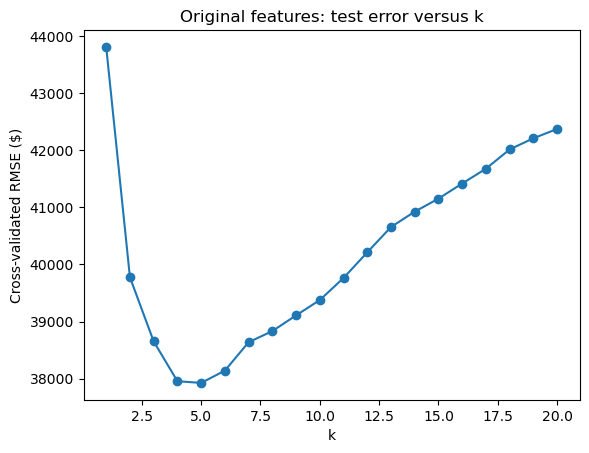

Best k: 5
RMSE: 37924


In [4]:
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

X_original = pd.get_dummies(df_ames[feature_sets[0]], dtype=int)
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

grid_k = GridSearchCV(
    pipeline,
    {"knn__n_neighbors": range(1, 21)},
    scoring="neg_mean_squared_error",
    cv=5
)
grid_k.fit(X_original, y_ames)

k_results = pd.DataFrame(grid_k.cv_results_)
k_results["RMSE"] = np.sqrt(-k_results["mean_test_score"])
plt.plot(k_results["param_knn__n_neighbors"].astype(int), k_results["RMSE"], marker="o")
plt.xlabel("k")
plt.ylabel("Cross-validated RMSE ($)")
plt.title("Original features: test error versus k")
plt.show()

print("Best k:", grid_k.best_params_["knn__n_neighbors"])
print("RMSE:", round(np.sqrt(-grid_k.best_score_)))

**Answer 2.** For the original five features, grid search chooses **k = 5**. The estimated test RMSE is **$37,924**. The plot shows RMSE for each k from 1 to 20.

3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

In [5]:
grid_metric = GridSearchCV(
    pipeline,
    {"knn__n_neighbors": range(1, 21),
     "knn__metric": ["euclidean", "manhattan"]},
    scoring="neg_mean_squared_error",
    cv=5
)
grid_metric.fit(X_original, y_ames)

print("Best parameters:", grid_metric.best_params_)
print("RMSE:", round(np.sqrt(-grid_metric.best_score_)))
print("RMSE from part 2:", round(np.sqrt(-grid_k.best_score_)))

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 5}
RMSE: 37924
RMSE from part 2: 37924


**Answer 3.** Searching both distance metrics still chooses **k = 5** and **Euclidean** distance, with RMSE **$37,924**. Adding Manhattan distance did not improve the result for these features.

4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

In [6]:
X_best = pd.get_dummies(df_ames[best_features], dtype=int)
grid_best = GridSearchCV(
    pipeline,
    {"knn__n_neighbors": [3, 5, 7, 10, 15, 20],
     "knn__metric": ["euclidean", "manhattan"],
     "knn__weights": ["uniform", "distance"]},
    scoring="neg_mean_squared_error",
    cv=5
)
grid_best.fit(X_best, y_ames)

print("Features:", best_features)
print("Best parameters:", grid_best.best_params_)
print("Estimated test RMSE:", round(np.sqrt(-grid_best.best_score_)))

Features: ['Gr Liv Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Lot Area', 'Neighborhood', 'Kitchen Qual', 'Fireplaces', 'Total Bath']
Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
Estimated test RMSE: 32355


**Answer 4.** Using the best features from part 1, grid search chooses **k = 5**, **Manhattan** distance, and **distance** weights. The estimated test RMSE is **$32,355**.

5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?


In [7]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("scale", StandardScaler()),
    ("linear", LinearRegression())
])
linear_scores = cross_val_score(
    linear_model, X_best, y_ames, scoring="neg_mean_squared_error", cv=5
)
linear_rmse = np.sqrt(-linear_scores.mean())
knn_rmse = np.sqrt(-grid_best.best_score_)

print("Linear regression RMSE:", round(linear_rmse))
print("Tuned kNN RMSE:", round(knn_rmse))

Linear regression RMSE: 32505
Tuned kNN RMSE: 32355


**Answer 5.** With the same features, linear regression has estimated test RMSE **$32,505**. The tuned kNN model is slightly better, by about **$150** in RMSE.

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [8]:
df = pd.read_csv("loans_full_schema.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (10000, 56)


,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0


count    10000.000000
mean        12.427524
std          5.001105
min          5.310000
25%          9.430000
50%         11.980000
75%         15.050000
max         30.940000
Name: interest_rate, dtype: float64

loan_amount      0
annual_income    0
grade            0
sub_grade        0
dtype: int64

grade
A     6.742631
B    10.524103
C    14.176698
D    19.113451
E    25.103403
F    29.401897
G    30.802500
Name: interest_rate, dtype: float64

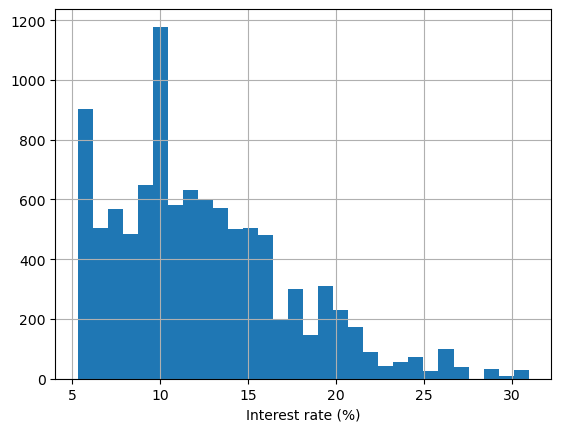

In [9]:
# Explore the target and a few possible predictors before fitting models.
display(df["interest_rate"].describe())
display(df[["loan_amount", "annual_income", "grade", "sub_grade"]].isna().sum())
display(df.groupby("grade")["interest_rate"].mean())
df["interest_rate"].hist(bins=30)
plt.xlabel("Interest rate (%)")
plt.show()

### Loan models

Use borrower information and loan terms, including the lender's grade and sub-grade. Leave out installment and repayment fields because they reveal the rate or occur after the loan is made.

In [10]:
from sklearn.tree import DecisionTreeRegressor

loan_features = [
    "loan_amount", "term", "annual_income", "delinq_2y",
    "inquiries_last_12m", "total_credit_lines", "open_credit_lines",
    "grade", "sub_grade", "homeownership", "verified_income", "loan_purpose"
]
X_loans = pd.get_dummies(df[loan_features], dtype=int)
y_loans = df["interest_rate"]

loan_linear = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())])
loan_knn = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=10))])
loan_tree = DecisionTreeRegressor(random_state=42)

linear_scores = cross_val_score(loan_linear, X_loans, y_loans,
                                scoring="neg_mean_squared_error", cv=5)
knn_scores = cross_val_score(loan_knn, X_loans, y_loans,
                             scoring="neg_mean_squared_error", cv=5)

# Tune the tree's size with grid search, as in the Topic 10-1 example.
tree_grid = GridSearchCV(
    loan_tree,
    {"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [1, 5, 10]},
    scoring="neg_mean_squared_error",
    cv=5
)
tree_grid.fit(X_loans, y_loans)

loan_errors = pd.Series({
    "Linear regression": np.sqrt(-linear_scores.mean()),
    "10-nearest neighbors": np.sqrt(-knn_scores.mean()),
    "Tuned decision tree": np.sqrt(-tree_grid.best_score_)
})
display(loan_errors.sort_values())
print("Tree parameters:", tree_grid.best_params_)
print("Lowest estimated test RMSE:", round(loan_errors.min(), 3), "percentage points")

Tuned decision tree     0.212168
Linear regression       0.222668
10-nearest neighbors    0.861283
dtype: float64

Tree parameters: {'max_depth': 10, 'min_samples_leaf': 10}
Lowest estimated test RMSE: 0.212 percentage points


**Loans result.** The tuned decision tree has the lowest cross-validated RMSE of the three models: **0.212 percentage points**. Grid search chooses `max_depth=10` and `min_samples_leaf=10`. These results apply to loans in this dataset, which contains accepted loans rather than all applications.